# KAN-43 — EXP-03: Slow-Moving Risk Model Benchmark
## for Slow-Moving Product Risk Detection in E-Commerce

**Phase**: Risk Model Benchmark & Temporal Validation
**Dependency**: EXP-02 (Frozen Strategy A Ground Truth)

**Research Questions**:
- **RQ1**: Which model achieves best overall multi-class classification performance?
- **RQ2**: Which model minimizes False Negative Rate (FNR) on High-Risk SKUs (CRITICAL + HIGH)?
- **RQ3**: How well do models handle extreme class imbalance (MEDIUM_RISK = 2.0%)?
- **RQ4**: Do complex ensemble models outperform simple baselines?

**Models Benchmarked**: Rule-Based Baseline, Logistic Regression, Random Forest, LightGBM, XGBoost

In [1]:
import sys, os, json
import pandas as pd
from pathlib import Path
from IPython.display import display, Markdown, Image

PROJECT_ROOT = Path(os.getcwd()).parent if os.getcwd().endswith('notebooks') else Path(os.getcwd())
sys.path.append(str(PROJECT_ROOT / 'scripts'))

from risk_model_benchmark import main as run_risk_benchmark
benchmark_summary = run_risk_benchmark()

00:52:03 │ INFO    │ ╔══════════════════════════════════════════════════════════════════════╗


00:52:03 │ INFO    │ ║  EXP-03 — Slow-Moving Risk Model Benchmark                        ║


00:52:03 │ INFO    │ ╚══════════════════════════════════════════════════════════════════════╝


00:52:03 │ INFO    │ ─── Leakage Audit ───


00:52:03 │ INFO    │   ✅ No leakage: 0 forbidden columns in feature matrix


...

00:52:11 │ INFO    │   ✅ Saved: risk_model_metrics.json


00:52:11 │ INFO    │   ✅ Saved: confusion_matrix_best.png


00:52:11 │ INFO    │   ✅ Saved: model_comparison.png


00:52:11 │ INFO    │   ✅ Saved: best_risk_model.pkl


00:52:11 │ INFO    │ 
🎉 EXP-03 Risk Model Benchmark completed in 8.2s


## 1. Benchmark Results Summary

In [2]:
df_bench = pd.read_csv(PROJECT_ROOT / 'reports' / 'risk_model_benchmark.csv')
display(df_bench.style
    .set_caption('EXP-03 Risk Model Benchmark (5-Fold Stratified CV)')
    .highlight_max(subset=['macro_f1_mean', 'high_risk_recall_mean', 'balanced_accuracy_mean'], color='lightgreen')
    .highlight_min(subset=['fnr_mean'], color='lightgreen')
    .format({
        'macro_f1_mean': '{:.4f}', 'weighted_f1_mean': '{:.4f}',
        'high_risk_recall_mean': '{:.4f}', 'fnr_mean': '{:.4f}',
        'macro_precision_mean': '{:.4f}', 'balanced_accuracy_mean': '{:.4f}'
    })
)

,model,macro_f1_mean,macro_f1_std,weighted_f1_mean,weighted_f1_std,macro_precision_mean,macro_precision_std,macro_recall_mean,macro_recall_std,balanced_accuracy_mean,balanced_accuracy_std,high_risk_recall_mean,high_risk_recall_std,high_risk_precision_mean,high_risk_precision_std,fnr_mean,fnr_std,fpr_mean,fpr_std
0,A: Rule-Based,0.4537,0.000000,0.6009,0.000000,0.4485,0.000000,0.541700,0.000000,0.5417,0.000000,0.9203,0.000000,0.985800,0.000000,0.0797,0.000000,0.395200,0.000000
1,B: Logistic Regression,0.6926,0.026800,0.8861,0.008300,0.7014,0.035300,0.745700,0.054100,0.7457,0.054100,0.9372,0.013000,0.990000,0.011500,0.0628,0.013000,0.331400,0.044800
2,C: Random Forest,0.7223,0.056800,0.9259,0.009900,0.7262,0.051800,0.732900,0.077000,0.7329,0.077000,0.9698,0.005400,0.992600,0.009000,0.0302,0.005400,0.191300,0.035300
3,D: LightGBM,0.6941,0.046400,0.9203,0.009400,0.7198,0.105900,0.692300,0.032500,0.6923,0.032500,0.9819,0.008500,0.978400,0.011000,0.0181,0.008500,0.136000,0.061000
4,E: XGBoost,0.7336,0.068400,0.9227,0.013300,0.7409,0.073000,0.730100,0.065700,0.7301,0.065700,0.9807,0.008900,0.985500,0.013500,0.0193,0.008900,0.138900,0.068000


## 2. Per-Class F1 Score Breakdown (RQ3)

In [3]:
with open(PROJECT_ROOT / 'reports' / 'risk_model_metrics.json') as f:
    metrics_json = json.load(f)

per_class_data = []
for model_name, m_dict in metrics_json['models'].items():
    row = {'Model': model_name}
    for label in ['CRITICAL', 'HIGH_RISK', 'MEDIUM_RISK', 'LOW_RISK']:
        row[label] = m_dict.get(f'per_class_f1_{label}_mean', 0)
    per_class_data.append(row)

df_per_class = pd.DataFrame(per_class_data)
display(df_per_class.style.set_caption('Per-Class F1 Scores across Models')
    .highlight_max(subset=['CRITICAL', 'HIGH_RISK', 'MEDIUM_RISK', 'LOW_RISK'], color='lightgreen')
    .format('{:.4f}')
)

ValueError: Unknown format code 'f' for object of type 'str'

## 3. Top Feature Importances (Selected Model)

In [4]:
fi = metrics_json.get('feature_importance', {})
if fi:
    df_fi = pd.DataFrame(list(fi.items()), columns=['Feature', 'Importance']).head(15)
    display(df_fi.style.set_caption(f'Top 15 Feature Importances ({metrics_json["selected_model"]})'))
else:
    print('No feature importances available.')

,Feature,Importance
0,forecast_7d,0.185114
1,demand_probability,0.167329
2,adi,0.116552
3,sales_last_30d,0.113570
4,sales_velocity_full,0.099827
5,zero_rate_full,0.050623
6,expected_demand_daily,0.042813
7,forecast_trend,0.034155
8,dsls,0.032780
9,zero_rate_90d,0.029148


## 4. Visualizations

### Model Performance Comparison

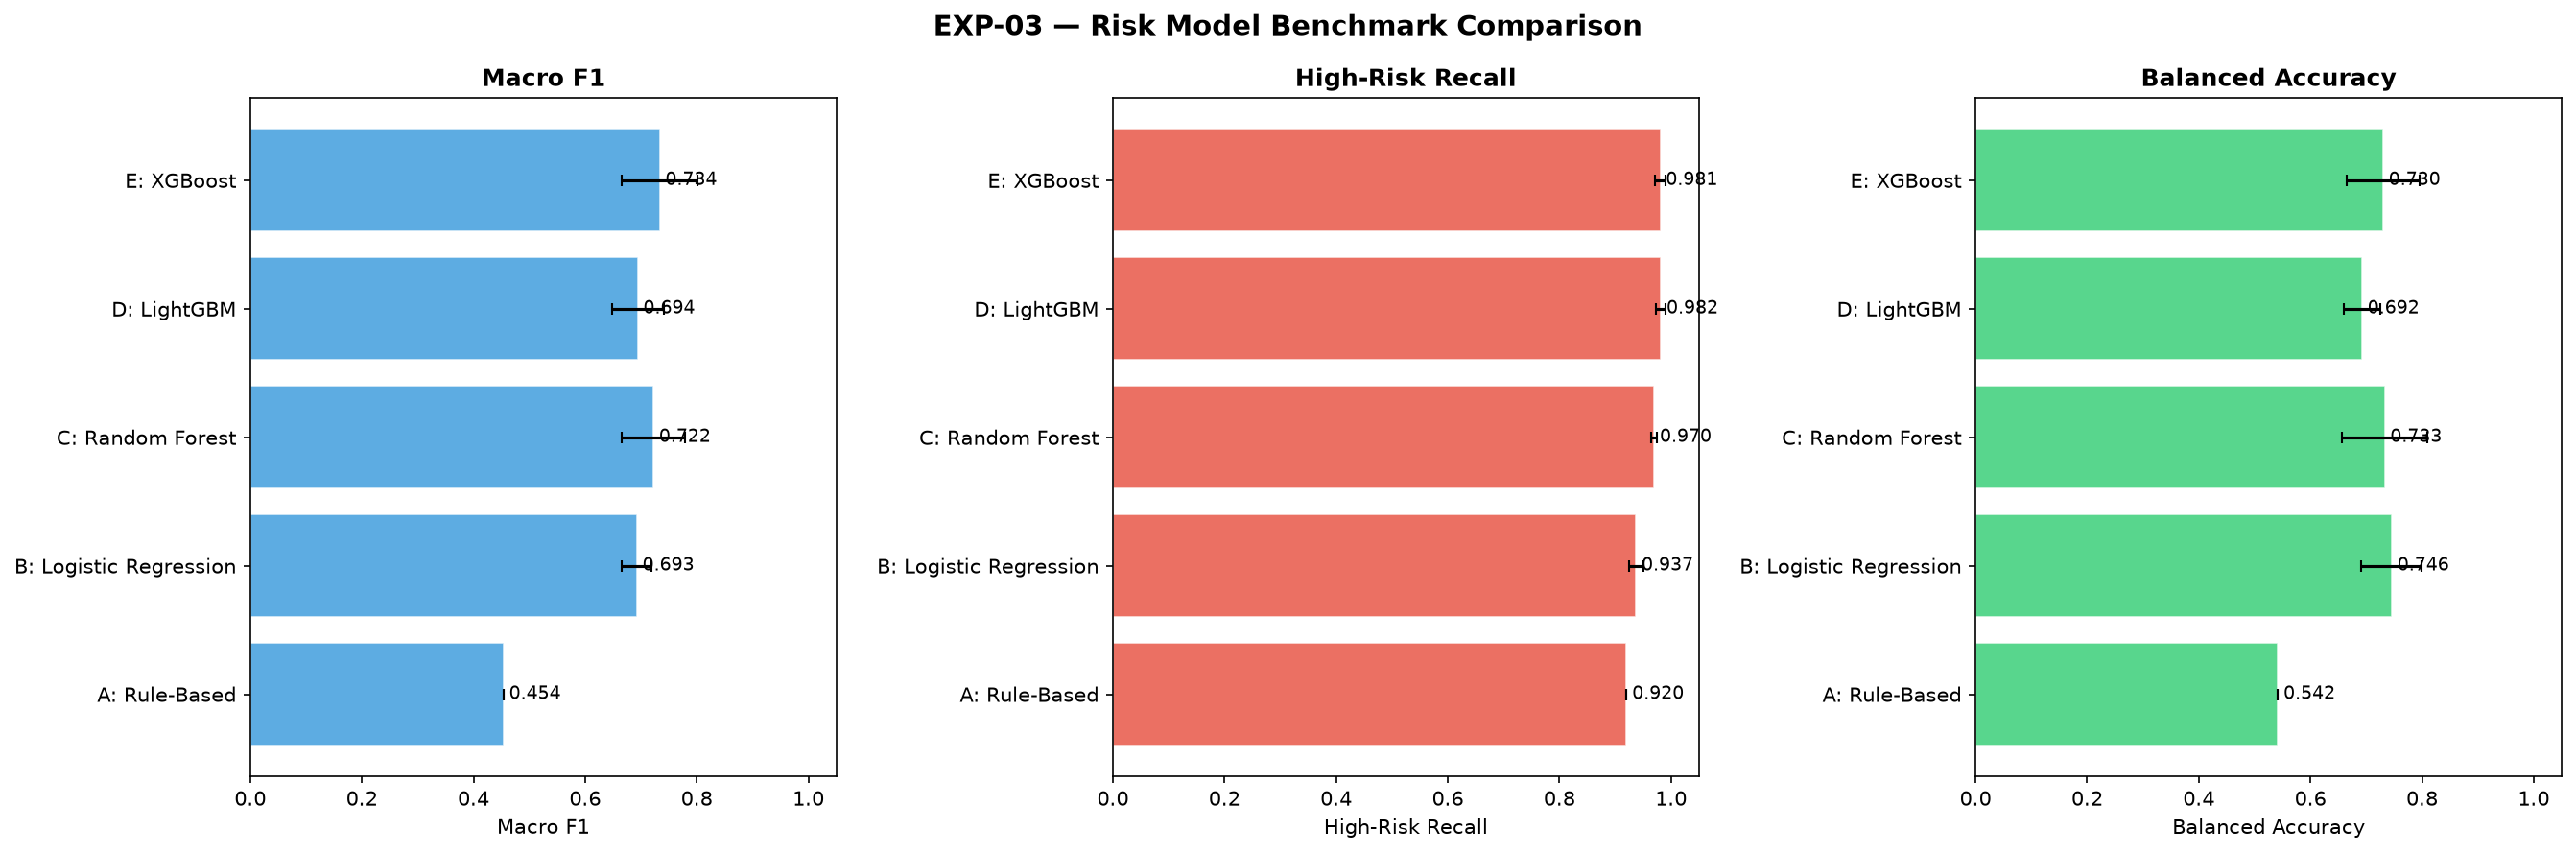

### Confusion Matrix (Selected Model)

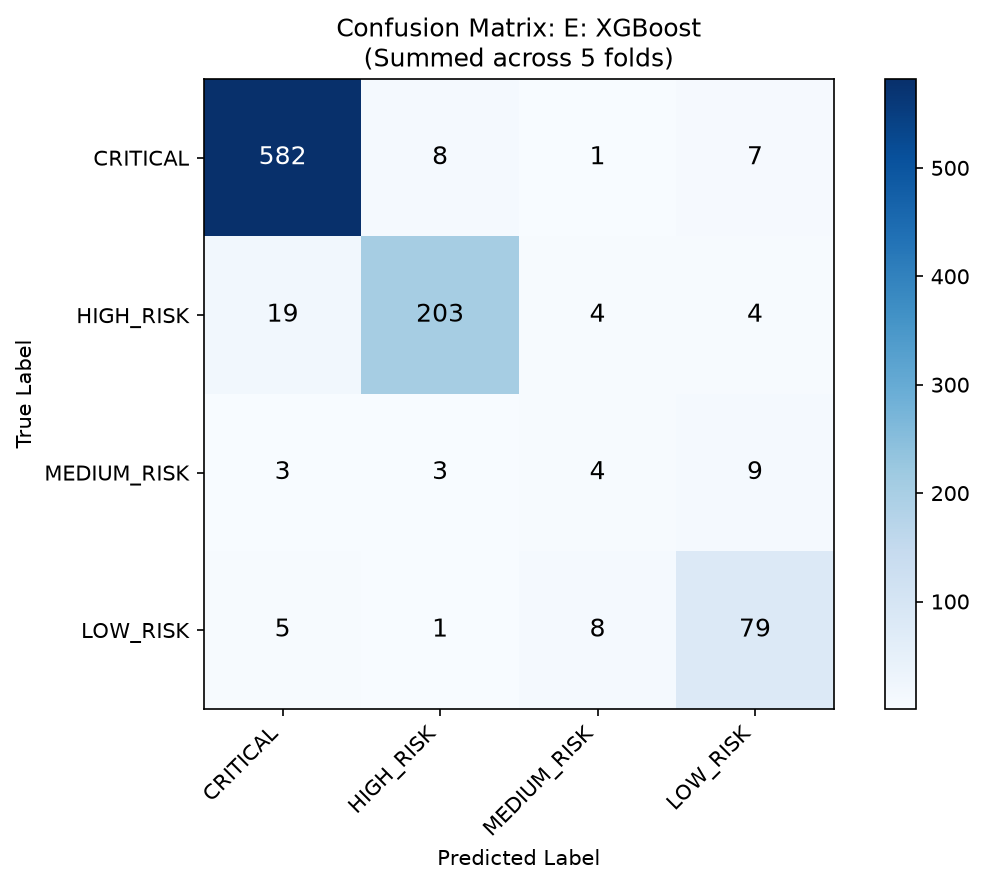

In [5]:
img_comp = PROJECT_ROOT / 'reports' / 'model_comparison.png'
img_cm = PROJECT_ROOT / 'reports' / 'confusion_matrix_best.png'

if img_comp.exists():
    display(Markdown('### Model Performance Comparison'))
    display(Image(filename=str(img_comp), width=900))

if img_cm.exists():
    display(Markdown('### Confusion Matrix (Selected Model)'))
    display(Image(filename=str(img_cm), width=600))

## 5. Selected Model & Academic Summary

In [6]:
print('=' * 75)
print(f'SELECTED MODEL: {metrics_json["selected_model"]}')
print(f'Selection Criteria: {metrics_json["selection_criteria"]}')
print('=' * 75)
print()
print('Key Highlights:')
print(f'  - Best Macro F1: {metrics_json["best_by_metric"]["macro_f1"]}')
print(f'  - Best High-Risk Recall: {metrics_json["best_by_metric"]["high_risk_recall"]}')
print(f'  - Lowest FNR: {metrics_json["best_by_metric"]["lowest_fnr"]}')

SELECTED MODEL: E: XGBoost
Selection Criteria: Highest High-Risk Recall among models with Macro F1 within 5% of the best. Prioritizes minimizing missed slow-moving SKUs.

Key Highlights:
  - Best Macro F1: E: XGBoost
  - Best High-Risk Recall: D: LightGBM
  - Lowest FNR: D: LightGBM
